In [6]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss, log_loss
)
import xgboost as xgb
import lightgbm as lgb

from sklearn.cluster import KMeans
import joblib

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 110


In [ ]:

# Load Training (2019-2024) and OOT Holdout (2025) Datasets
train_df = pd.read_csv("../data/synthetic_portfolio/train_portfolio_2019_2024.csv", keep_default_na=False, na_values=[""])
oot_df   = pd.read_csv("../data/synthetic_portfolio/oot_portfolio_2025_2026.csv", keep_default_na=False, na_values=[""])

with open("../data/model_artefacts/selected_features_metadata.json", "r") as f:
    meta = json.load(f)

features = meta["final_14_features"]
num_cols = meta["numerical_features"]
cat_cols = meta["categorical_features"]
target   = "possession_flag"

X_train, y_train, ead_train = train_df[features], train_df[target], train_df["current_balance"]
X_oot, y_oot, ead_oot       = oot_df[features], oot_df[target], oot_df["current_balance"]

# Custom Winsorizer (clips at 1st and 99th percentiles learned on fit)
class QuantileWinsorizer(BaseEstimator, TransformerMixin):
    def __init__(self, lower_quantile=0.01, upper_quantile=0.99):
        self.lower_quantile = lower_quantile
        self.upper_quantile = upper_quantile
        
    def fit(self, X, y=None):
        X_arr = np.asarray(X, dtype=float)
        self.lower_bounds_ = np.nanquantile(X_arr, self.lower_quantile, axis=0)
        self.upper_bounds_ = np.nanquantile(X_arr, self.upper_quantile, axis=0)
        return self
        
    def transform(self, X):
        X_arr = np.asarray(X, dtype=float)
        return np.clip(X_arr, self.lower_bounds_, self.upper_bounds_)

print(f"Loaded Training Set : {X_train.shape[0]:,} accounts (Base PPGD: {y_train.mean()*100:.2f}%)")
print(f"Loaded OOT 2025 Set : {X_oot.shape[0]:,} accounts (Base PPGD: {y_oot.mean()*100:.2f}%)")

Loaded Training Set : 61,048 accounts (Base PPGD: 6.80%)
Loaded OOT 2025 Set : 23,689 accounts (Base PPGD: 7.36%)


### Model Pipeline Creation

In [3]:
# Preprocessor for all models
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("winsorizer", QuantileWinsorizer(0.01, 0.99)),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
])

preprocessor_std = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

print("Applying standard preprocessing pipeline to all data...")
X_train_prep = preprocessor_std.fit_transform(X_train)
X_oot_prep   = preprocessor_std.transform(X_oot)
print(f"Preprocessed Train Shape: {X_train_prep.shape}")

Applying standard preprocessing pipeline to all data...
Preprocessed Train Shape: (61048, 21)


### Hyperparameter Tuning with Stratified K-Fold

In [ ]:
cv_scheme = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define models directly
models = {
    "Logistic_Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random_Forest": RandomForestClassifier(random_state=42, n_jobs=-1),
    "LightGBM": lgb.LGBMClassifier(objective="binary", random_state=42, n_jobs=-1, verbose=-1),
    "XGBoost": xgb.XGBClassifier(objective="binary:logistic", eval_metric="logloss", tree_method="hist", random_state=42, n_jobs=-1)
}

param_grids = {
    "Logistic_Regression": {
        "C": [0.001, 0.005, 0.01], # Constrained linear baseline
        "penalty": ["l2"],
        "solver": ["lbfgs"]
    },
    "Random_Forest": {
        "n_estimators": [150, 250], 
        "max_depth": [6, 8, 10],
        "min_samples_leaf": [30, 50, 100],
        "max_features": ["sqrt", 0.5]
    },
    "LightGBM": {
        "n_estimators": [200, 350],
        "learning_rate": [0.03, 0.05],
        "num_leaves": [15, 31],
        "max_depth": [4, 6],
        "min_child_samples": [30, 50, 100],
        "subsample": [0.8, 1.0],
        "colsample_bytree": [0.7, 0.9]
    },
    "XGBoost": {
        "n_estimators": [250, 400, 500],
        "learning_rate": [0.02, 0.04, 0.06],
        "max_depth": [4, 5, 6],
        "min_child_weight": [10, 20, 40], # Lowered so XGBoost captures non-linear interactions
        "subsample": [0.8, 0.9],
        "colsample_bytree": [0.7, 0.85],
        "reg_alpha": [0.0, 0.5, 1.0],
        "reg_lambda": [0.5, 1.0, 2.0]
    }
}

tuned_models = {}
comparison_records = []

for name in models.keys():
    print(f"Tuning {name}...")
    search = RandomizedSearchCV(
        estimator=models[name],
        param_distributions=param_grids[name],
        n_iter=min(10, int(np.prod([len(v) for v in param_grids[name].values()]))),
        scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision", "neg_log_loss": "neg_log_loss"},
        refit="roc_auc", # Optimise directly for Gini / Discriminatory power
        cv=cv_scheme,
        random_state=42,
        n_jobs=-1
    )
    search.fit(X_train_prep, y_train)
    best_model = search.best_estimator_
    tuned_models[name] = best_model
    
    # Evaluate on Train and OOT
    train_probs = best_model.predict_proba(X_train_prep)[:, 1] #type: ignore
    oot_probs   = best_model.predict_proba(X_oot_prep)[:, 1] # type: ignore
    
    train_auc = roc_auc_score(y_train, train_probs)
    oot_auc   = roc_auc_score(y_oot, oot_probs)
    
    oot_obs_ead_ppgd  = (y_oot * ead_oot).sum() / ead_oot.sum() * 100
    oot_pred_ead_ppgd = (oot_probs * ead_oot).sum() / ead_oot.sum() * 100
    
    comparison_records.append({
        "Model": name,
        "CV_ROC_AUC": round(search.cv_results_["mean_test_roc_auc"][search.best_index_], 4),
        "Train_Gini": round(2 * train_auc - 1, 4),
        "OOT_ROC_AUC": round(oot_auc, 4),
        "OOT_Gini": round(2 * oot_auc - 1, 4),
        "OOT_PR_AUC": round(average_precision_score(y_oot, oot_probs), 4),
        "OOT_Brier": round(brier_score_loss(y_oot, oot_probs), 4),
        "OOT_Obs_Vol_%": round(y_oot.mean() * 100, 2),
        "OOT_Pred_Vol_%": round(oot_probs.mean() * 100, 2),
        "OOT_Obs_EAD_%": round(oot_obs_ead_ppgd, 2),
        "OOT_Pred_EAD_%": round(oot_pred_ead_ppgd, 2)
    })

comparison_df = pd.DataFrame(comparison_records).sort_values(by="OOT_Gini", ascending=False)
print("\nMODEL COMPARISON SUMMARY (SORTED BY OOT GINI):")
display(comparison_df)

Tuning Logistic_Regression...
Tuning Random_Forest...
Tuning LightGBM...
Tuning XGBoost...

MODEL COMPARISON SUMMARY (SORTED BY OOT GINI):


,Model,CV_ROC_AUC,Train_Gini,OOT_ROC_AUC,OOT_Gini,OOT_PR_AUC,OOT_Brier,OOT_Obs_Vol_%,OOT_Pred_Vol_%,OOT_Obs_EAD_%,OOT_Pred_EAD_%
0,Logistic_Regression,0.8326,0.6675,0.8191,0.6382,0.3522,0.0572,7.36,7.42,8.53,8.54
3,XGBoost,0.8287,0.7263,0.8165,0.6331,0.3445,0.0576,7.36,7.30,8.53,8.40
2,LightGBM,0.8278,0.7318,0.8162,0.6323,0.3415,0.0577,7.36,7.36,8.53,8.52
1,Random_Forest,0.8124,0.7254,0.7978,0.5957,0.3058,0.0601,7.36,7.29,8.53,8.40


### Models & Generate Scored Evaluation Datasets

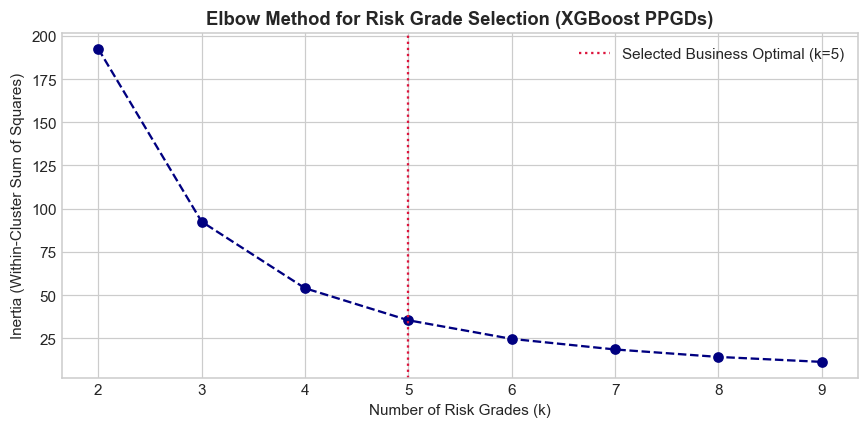


 XGBoost + K-MEANS RISK GRADE SCALE (DEVELOPMENT SET):


,Risk_Grade,Train_Accounts,Min_PPGD,Max_PPGD,Grade_Pooled_PPGD,Observed_Default_Rate
0,1,40114,0.17%,5.23%,2.11%,1.57%
1,2,12631,5.23%,13.58%,8.37%,7.94%
2,3,5198,13.58%,26.48%,18.80%,19.66%
3,4,2238,26.48%,46.34%,34.14%,39.23%
4,5,867,46.36%,87.16%,58.51%,71.74%


In [10]:


# Generate Scored DataFrames with Continuous PPGDs for all models
train_scored = train_df[["account_id", "default_quarter", "default_year", "current_balance", "current_ltv", target]].copy()
oot_scored   = oot_df[["account_id", "default_quarter", "default_year", "current_balance", "current_ltv", target]].copy()

for name, model in tuned_models.items():
    train_scored[f"pred_{name}"] = model.predict_proba(X_train_prep)[:, 1]
    oot_scored[f"pred_{name}"]   = model.predict_proba(X_oot_prep)[:, 1]

# Select XGBoost as the Champion Model for Risk Grade Segmentation
champion_name  = "XGBoost"
champion_model = tuned_models[champion_name]

# Set PPGD column from XGBoost
train_scored["PPGD"] = train_scored["pred_XGBoost"]
oot_scored["PPGD"]   = oot_scored["pred_XGBoost"]

# 2. K-Means Elbow Method to visually justify the number of Risk Grades
train_ppgds = train_scored[["PPGD"]]
inertia = []
k_range = range(2, 10)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(train_ppgds)
    inertia.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range, inertia, marker='o', linestyle='--', color='navy')
plt.axvline(x=5, color='crimson', linestyle=':', label='Selected Business Optimal (k=5)')
plt.title("Elbow Method for Risk Grade Selection (XGBoost PPGDs)", fontweight='bold')
plt.xlabel("Number of Risk Grades (k)")
plt.ylabel("Inertia (Within-Cluster Sum of Squares)")
plt.xticks(k_range)
plt.legend()
plt.tight_layout()
plt.show()

# 3. Fit K-Means on Training XGBoost PPGDs to create Discrete Risk Grades
N_GRADES = 5
kmeans_grader = KMeans(n_clusters=N_GRADES, random_state=42, n_init=20)
kmeans_grader.fit(train_ppgds)

# Order clusters from Grade 1 (Lowest PPGD) to Grade 5 (Highest PPGD)
sorted_clusters = np.argsort(kmeans_grader.cluster_centers_.flatten())
cluster_to_grade = {int(old_c): int(new_g + 1) for new_g, old_c in enumerate(sorted_clusters)}

# Apply consistent K-Means grade boundaries to Train and OOT Holdout
train_scored["Risk_Grade"] = pd.Series(kmeans_grader.predict(train_scored[["PPGD"]])).map(cluster_to_grade)
oot_scored["Risk_Grade"]   = pd.Series(kmeans_grader.predict(oot_scored[["PPGD"]])).map(cluster_to_grade)

# Calculate Long-Run Pooled PPGD per Risk Grade from Training set and map to both sets
grade_pooled_ppgd = train_scored.groupby("Risk_Grade")["PPGD"].mean().to_dict()
train_scored["Grade_PPGD"] = train_scored["Risk_Grade"].map(grade_pooled_ppgd)
oot_scored["Grade_PPGD"]   = oot_scored["Risk_Grade"].map(grade_pooled_ppgd)

# Display the derived Risk Grade Scale
grade_scale_df = train_scored.groupby("Risk_Grade").agg(
    Train_Accounts=(target, "count"),
    Min_PPGD=("PPGD", "min"),
    Max_PPGD=("PPGD", "max"),
    Grade_Pooled_PPGD=("PPGD", "mean"),
    Observed_Default_Rate=(target, "mean")
).reset_index()

print(f"\n {champion_name} + K-MEANS RISK GRADE SCALE (DEVELOPMENT SET):")
display(grade_scale_df.style.format({
    "Min_PPGD": "{:.2%}", "Max_PPGD": "{:.2%}", 
    "Grade_Pooled_PPGD": "{:.2%}", "Observed_Default_Rate": "{:.2%}"
}))

#Save the preprocessor, champion model, and K-Means grader
joblib.dump(preprocessor_std, "../data/model_artefacts/global_preprocessor")
joblib.dump(champion_model, "../data/model_artefacts/champion_xgboost_model.pkl")
joblib.dump(kmeans_grader, "../data/model_artefacts/kmeans_risk_grader.pkl")

for name, model in tuned_models.items():
    joblib.dump(model, f"../data/model_artefacts/{name}_model.pkl")

train_scored.to_csv("../data/model_artefacts/train_scored_predictions.csv", index=False)
oot_scored.to_csv("../data/model_artefacts/oot_scored_predictions.csv", index=False)
